# Martingale optimal transport for multi-date event contracts

**Synthetic experiment | October 29, 2026**

We distinguish (i) ordinary couplings with only static marginals; (ii) martingale
couplings that permit self-financing dynamic hedge interpretation. The latter
are valid only for an appropriately discounted, dynamically tradable asset.

A conditional or sequence-based prediction contract on unrelated outcomes
**does not** satisfy these martingale restrictions merely because it is traded.


In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
# Resolve both running from the repository root and from notebooks/.
candidates = [Path.cwd() / 'src', Path.cwd().parent / 'src']
for p in candidates:
    if (p/'parity_ot').is_dir():
        sys.path.insert(0, str(p))
        break
from parity_ot.examples import two_date_underlying, three_date_underlying


## Two dates: $S_1=110$ followed by $S_2\le90$

Assume $S_1\in\{90,110\}$ with equal probabilities and
$S_2\in\{70,90,110,130\}$ uniformly. The target payoff is
$H=\mathbf 1_{\{S_1=110, S_2\le90\}}$.

Ordinary OT uses only the marginals. MOT also enforces
$\mathbb E[(S_2-S_1)\mathbf1_{\{S_1=x\}}]=0$ for each $x$.


In [2]:
e = two_date_underlying()
print('Ordinary OT:', e['ot'].lower, e['ot'].upper)
print('Martingale OT:', e['mot'].lower, e['mot'].upper)
assert np.isclose(e['mot'].lower, 1/12)
assert np.isclose(e['mot'].upper, .25)
assert e['mot'].verify(e['payoff'])


Ordinary OT: 0.0 0.5
Martingale OT: 0.08333333333333334 0.25


### Explicit pathwise hedge certificate

Let $G=\mathbf1_{\{S_1=110\}}(S_2-S_1)$, a predictable dynamic gain.
Then

$$
\frac13\mathbf1_{\{S_1=110\}}-\frac13\mathbf1_{\{S_2=110\}}-
\frac1{60}G
\le H\le
\mathbf1_{\{S_2=130\}}-\frac1{20}G.
$$

The portfolio costs are $1/12$ and $1/4$, proving sharpness together
with the primal optimizer.

In [3]:
s = e['states']
G = (s[:,0] == 110)*(s[:,1]-s[:,0])
hedge_lower = (s[:,0] == 110)/3 - (s[:,1] == 110)/3 - G/60
hedge_upper = (s[:,1] == 130) - G/20
assert np.all(hedge_lower <= e['payoff'] + 1e-10)
assert np.all(e['payoff'] <= hedge_upper + 1e-10)
print('All eight states pass both pathwise hedge inequalities.')


All eight states pass both pathwise hedge inequalities.


## A new joint quote sharpens the interval

Add the *hypothetical* joint claim $Q(S_1=110,S_2=130)=0.20$. This is
not a market observation.

In [4]:
aug = two_date_underlying(extra_joint_quote=.20)
print('MOT + one joint quote:', aug['mot'].lower, aug['mot'].upper)
assert np.allclose([aug['mot'].lower,aug['mot'].upper],[.1,.2])


MOT + one joint quote: 0.1 0.2


## Three dates with full-information conditioning

We add a third price marginal on $\{50,70,90,110,130,150\}$ and price
$S_1=110$, then $S_2\le90$, then $S_3\ge130$. Constraints on
$\mathbb E[S_3-S_2\mid S_1,S_2]$ use the *complete observed history*,
not just $S_2$. The payoff is discretely monitored at three dates.

In [5]:
f=three_date_underlying()
print('Three-date ordinary OT:',f['ot'].lower,f['ot'].upper)
print('Three-date full-filtration MOT:',f['mot'].lower,f['mot'].upper)
print('Discrete upper barrier ordinary OT:',f['barrier_ot'].lower,f['barrier_ot'].upper)
print('Discrete upper barrier MOT:',f['barrier_mot'].lower,f['barrier_mot'].upper)
assert f['mot'].verify(f['payoff'])
assert np.isclose(f['mot'].upper,1/16)


Three-date ordinary OT: 0.0 0.25
Three-date full-filtration MOT: 0.0 0.0625
Discrete upper barrier ordinary OT: 0.25 0.5
Discrete upper barrier MOT: 0.275 0.375


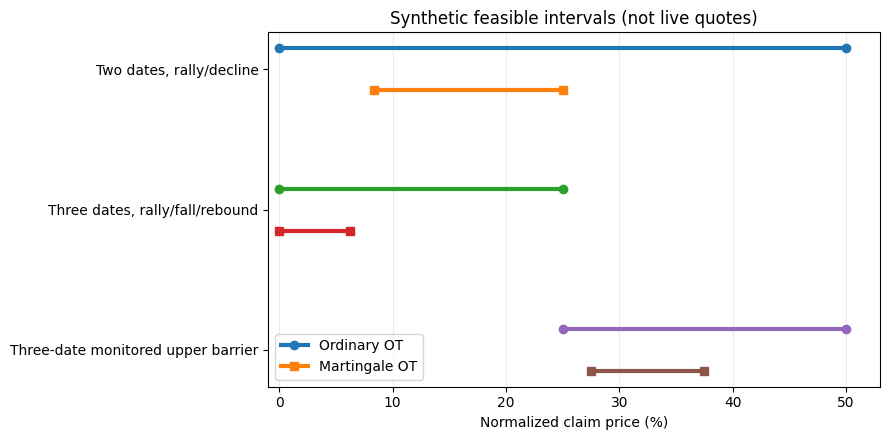

In [6]:
cases = [
 ('Two dates, rally/decline',e['ot'],e['mot']),
 ('Three dates, rally/fall/rebound',f['ot'],f['mot']),
 ('Three-date monitored upper barrier',f['barrier_ot'],f['barrier_mot']),
]
fig, ax=plt.subplots(figsize=(9,4.5))
for i,(label,o,m) in enumerate(cases):
 y=2.3-i
 ax.plot([o.lower*100,o.upper*100],[y+.15,y+.15],marker='o',linewidth=3,
         label='Ordinary OT' if i==0 else None)
 ax.plot([m.lower*100,m.upper*100],[y-.15,y-.15],marker='s',linewidth=3,
         label='Martingale OT' if i==0 else None)
ax.set_yticks([2.3,1.3,.3],[x[0] for x in cases])
ax.set_xlim(-1,53)
ax.grid(axis='x',alpha=.25)
ax.set_xlabel('Normalized claim price (%)')
ax.legend()
ax.set_title('Synthetic feasible intervals (not live quotes)')
plt.tight_layout()
plt.show()


## Limitations and next steps

- Finite support is a model assumption, not a continuous-time barrier result.
- We have not acquired any option surface or prediction-market quote.
- Pricing-measure probabilities should not be confused with forecast probabilities.
- Bid/ask spreads, fees, market depth and settlement mismatches are excluded.
- Causal/adapted transport requires a specified pair of information processes;
  chronology alone does not create a causal coupling constraint.

See `manuscript/main.tex` for proofs and `research/` for hypotheses.